In [ ]:
# ============================================================
# CELL 1 — Imports & Setup
# ============================================================
import os, time, warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
os.makedirs('/content/outputs', exist_ok=True)

print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Enable mixed precision — doubles throughput on modern GPUs
tf.keras.mixed_precision.set_global_policy('mixed_float16')
print("Mixed precision policy:", tf.keras.mixed_precision.global_policy().name)

TF version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: mixed_float16


In [ ]:
import os, zipfile, shutil

DRIVE = "/content/drive/MyDrive"
OUT = "/content/NIH_ChestXray14"

# Find ZIP files in Google Drive (up to 5 folder levels deep)
zips = []

for root, dirs, files in os.walk(DRIVE):
    depth = root.replace(DRIVE, "").count(os.sep)
    if depth > 5:
        dirs[:] = []
        continue

    for f in files:
        if f.lower().endswith(".zip"):
            zips.append(os.path.join(root, f))

print("ZIP files found:")
for i, z in enumerate(zips):
    size_gb = os.path.getsize(z) / (1024**3)
    print(f"[{i}] {z}  ({size_gb:.2f} GB)")

if not zips:
    raise FileNotFoundError("No ZIP files found in Google Drive.")

# Automatically choose the largest ZIP — almost certainly the dataset
zip_path = max(zips, key=os.path.getsize)

print(f"\nUsing dataset ZIP:")
print(zip_path)

os.makedirs(OUT, exist_ok=True)

print("\nExtracting...")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(OUT)

print("\n✅ DATASET RESTORED")
print("Location:", OUT)

print("\nTop-level contents:")
for item in os.listdir(OUT):
    print(" -", item)

ZIP files found:
[0] /content/drive/MyDrive/archive (2).zip  (2.30 GB)

Using dataset ZIP:
/content/drive/MyDrive/archive (2).zip

Extracting...

✅ DATASET RESTORED
Location: /content/NIH_ChestXray14

Top-level contents:
 - BBox_List_2017_Official_NIH.csv
 - train_val_list_NIH.txt
 - pretrained_model.h5
 - Data_Entry_2017.csv
 - test_list_NIH.txt
 - images-224


In [ ]:
# ============================================================
# CELL 2 — Index All ChestX-ray14 Images
# ============================================================

base_path = "/content/NIH_ChestXray14"

# Actual image directory inside the ZIP
image_dir = os.path.join(
    base_path,
    "images-224",
    "images-224"
)

image_path_dict = {}

for fname in os.listdir(image_dir):

    if fname.lower().endswith((".png", ".jpg", ".jpeg")):
        image_path_dict[fname] = os.path.join(
            image_dir,
            fname
        )

print(f"Base path: {base_path}")
print(f"Image directory: {image_dir}")
print(f"Total images indexed: {len(image_path_dict):,}")

if len(image_path_dict) == 0:
    raise RuntimeError("No images found.")

print("✓ ChestX-ray14 image indexing complete.")
print("✓ Source images: 224×224")
print("✓ Training pipeline will resize them to 320×320")

Base path: /content/NIH_ChestXray14
Image directory: /content/NIH_ChestXray14/images-224/images-224
Total images indexed: 112,120
✓ ChestX-ray14 image indexing complete.
✓ Source images: 224×224
✓ Training pipeline will resize them to 320×320


In [ ]:
# ============================================================
# CELL 3 — Load CSV, Create Multi-Label Columns
# ============================================================
CLASSES = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation',
    'Edema', 'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia'
]
NUM_CLASSES = len(CLASSES)

csv_path = os.path.join(base_path, 'Data_Entry_2017.csv')
df = pd.read_csv(csv_path)

for cls in CLASSES:
    df[cls] = df['Finding Labels'].apply(lambda x: 1 if cls in x else 0)

df['image_path'] = df['Image Index'].map(image_path_dict)
df = df.dropna(subset=['image_path'])

print(f"CSV shape: {df.shape}")
print(f"Missing paths: {df['image_path'].isna().sum()}")
print(f"\nDisease counts:\n{df[CLASSES].sum().sort_values(ascending=False)}")

CSV shape: (112120, 27)
Missing paths: 0

Disease counts:
Infiltration          19870
Effusion              13307
Atelectasis           11535
Nodule                 6323
Mass                   5746
Pneumothorax           5298
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2772
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1353
Hernia                  227
dtype: int64


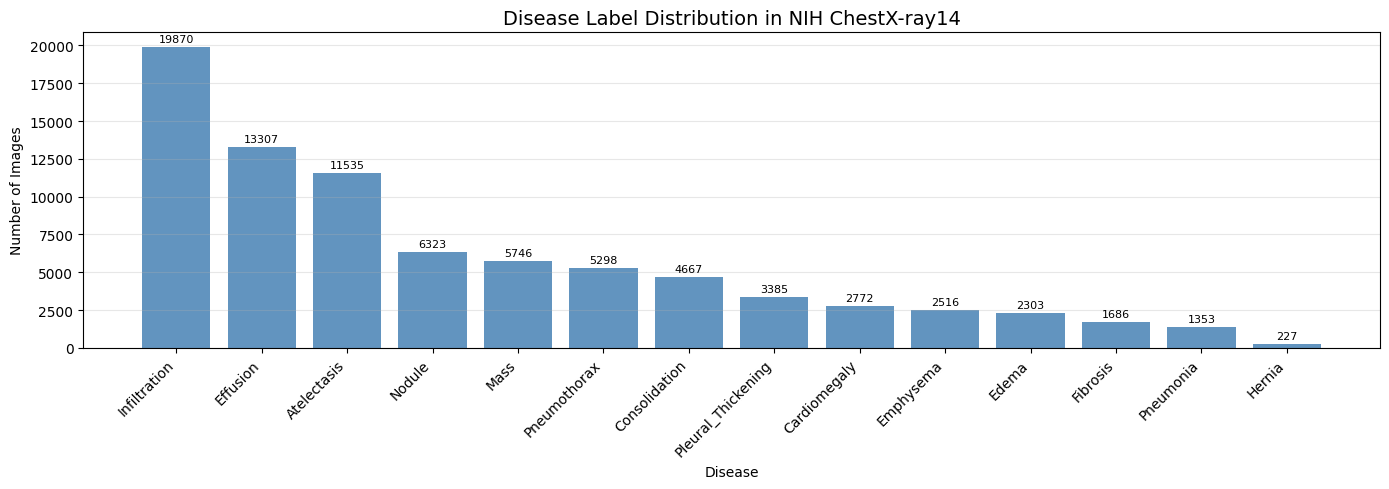

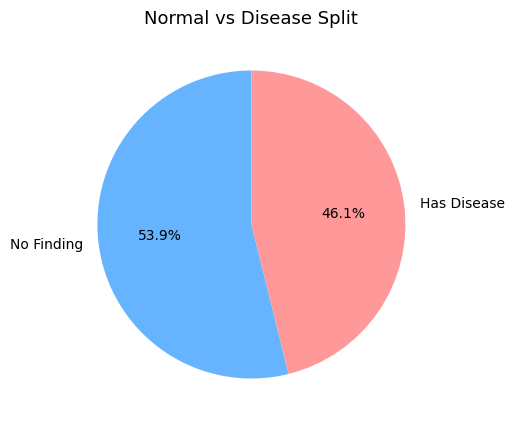

No Finding: 60412 (53.9%)
Has Disease: 51708 (46.1%)


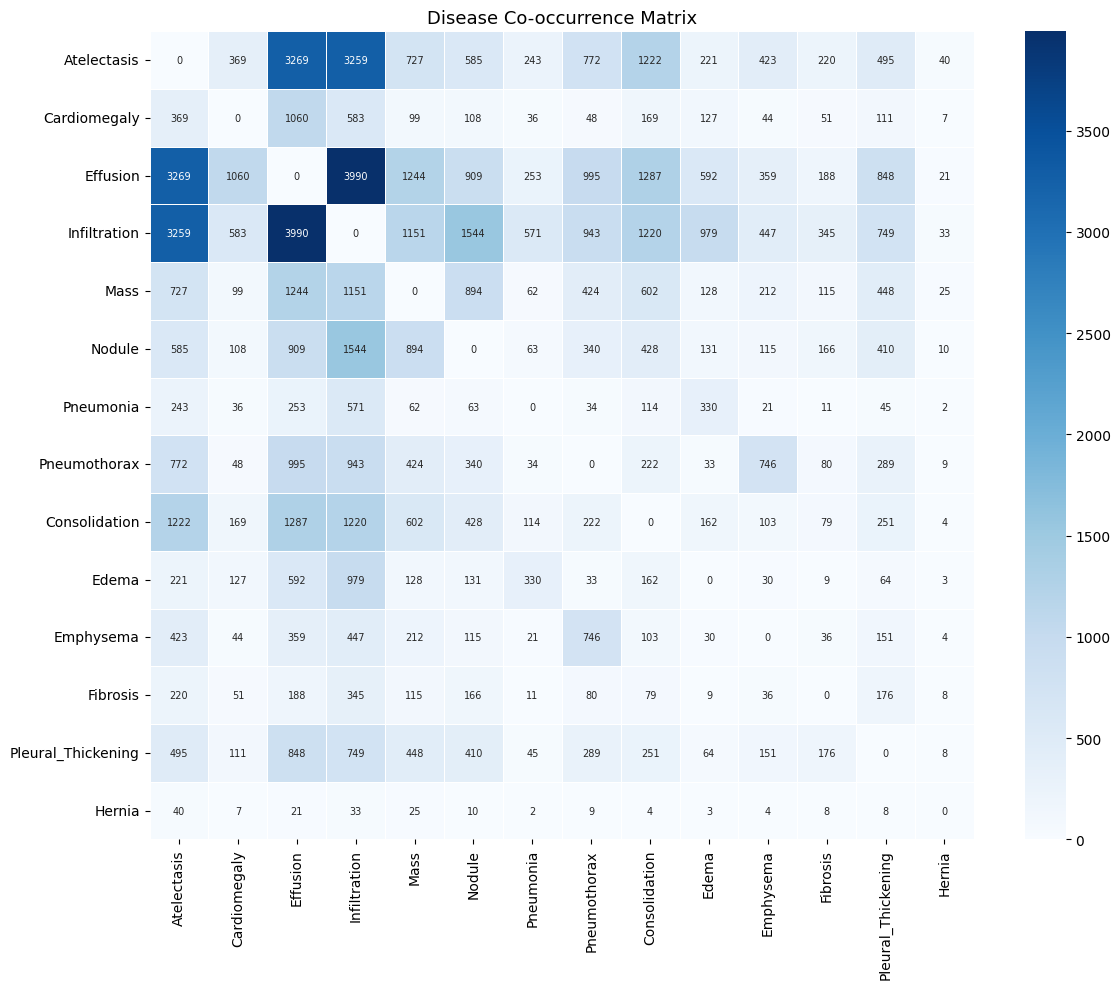

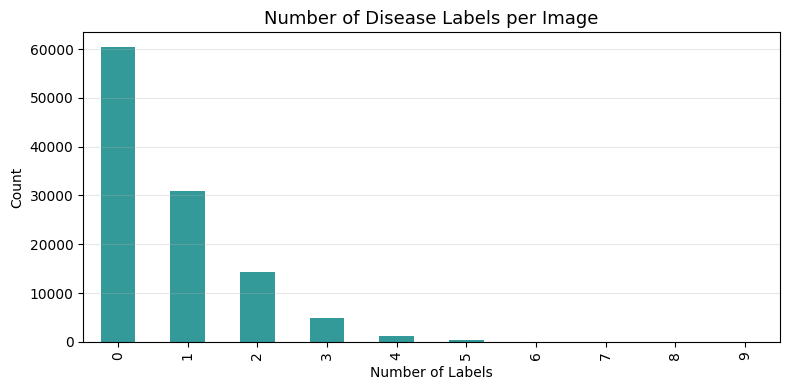

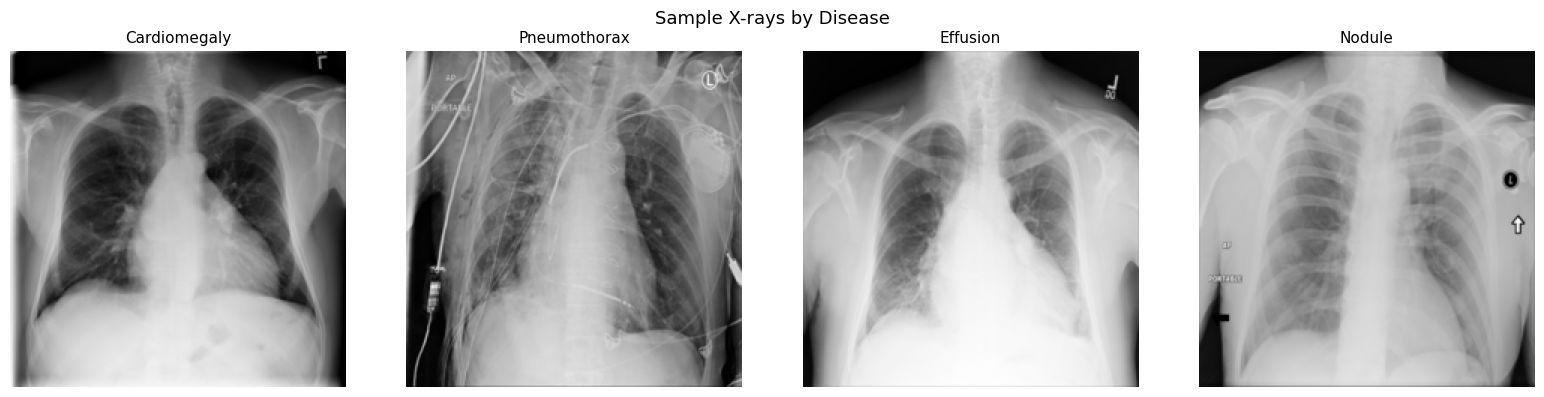

EDA COMPLETE
Total images: 112,120
Number of disease classes: 14
No Finding images: 60,412
Images with at least one disease: 51,708
Average labels per image: 0.72

Plots saved to:
/content/outputs/


In [ ]:
# ============================================================
# CELL 4 — Exploratory Data Analysis (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Make sure output directory exists
os.makedirs('/content/outputs', exist_ok=True)


# ============================================================
# 1. Disease Distribution
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))

disease_counts = df[CLASSES].sum().sort_values(ascending=False)

bars = ax.bar(
    disease_counts.index,
    disease_counts.values,
    color='steelblue',
    alpha=0.85
)

ax.set_title(
    'Disease Label Distribution in NIH ChestX-ray14',
    fontsize=14
)
ax.set_ylabel('Number of Images')
ax.set_xlabel('Disease')

plt.xticks(rotation=45, ha='right')

for bar, val in zip(bars, disease_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        str(int(val)),
        ha='center',
        va='bottom',
        fontsize=8
    )

ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    '/content/outputs/disease_distribution.png',
    dpi=150
)

plt.show()


# ============================================================
# 2. No Finding vs Disease Ratio
# ============================================================

n_normal = (df['Finding Labels'] == 'No Finding').sum()
n_disease = len(df) - n_normal

fig, ax = plt.subplots(figsize=(5, 5))

ax.pie(
    [n_normal, n_disease],
    labels=['No Finding', 'Has Disease'],
    autopct='%1.1f%%',
    colors=['#66b3ff', '#ff9999'],
    startangle=90
)

ax.set_title(
    'Normal vs Disease Split',
    fontsize=13
)

plt.savefig(
    '/content/outputs/normal_vs_disease.png',
    dpi=150
)

plt.show()

print(
    f"No Finding: {n_normal} "
    f"({100 * n_normal / len(df):.1f}%)"
)

print(
    f"Has Disease: {n_disease} "
    f"({100 * n_disease / len(df):.1f}%)"
)


# ============================================================
# 3. Multi-Label Disease Co-occurrence
# ============================================================

cooccurrence = df[CLASSES].T.dot(df[CLASSES])

# Remove diagonal because it represents individual disease counts
np.fill_diagonal(cooccurrence.values, 0)

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    cooccurrence,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=ax,
    linewidths=0.5,
    annot_kws={'size': 7}
)

ax.set_title(
    'Disease Co-occurrence Matrix',
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    '/content/outputs/cooccurrence_matrix.png',
    dpi=150
)

plt.show()


# ============================================================
# 4. Number of Labels per Image
# ============================================================

df['label_count'] = df[CLASSES].sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))

df['label_count'].value_counts().sort_index().plot(
    kind='bar',
    ax=ax,
    color='teal',
    alpha=0.8
)

ax.set_title(
    'Number of Disease Labels per Image',
    fontsize=13
)

ax.set_xlabel('Number of Labels')
ax.set_ylabel('Count')

ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    '/content/outputs/labels_per_image.png',
    dpi=150
)

plt.show()


# ============================================================
# 5. Sample X-rays by Disease
# ============================================================

sample_diseases = [
    'Cardiomegaly',
    'Pneumothorax',
    'Effusion',
    'Nodule'
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

for ax, disease in zip(axes, sample_diseases):

    sample_rows = df[df[disease] == 1]

    if len(sample_rows) == 0:
        ax.set_title(f'{disease}\nNo sample')
        ax.axis('off')
        continue

    sample_row = sample_rows.iloc[0]

    img = plt.imread(sample_row['image_path'])

    ax.imshow(
        img,
        cmap='gray'
    )

    ax.set_title(
        disease,
        fontsize=11
    )

    ax.axis('off')

plt.suptitle(
    'Sample X-rays by Disease',
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    '/content/outputs/sample_images.png',
    dpi=150
)

plt.show()


# ============================================================
# EDA Summary
# ============================================================

print("=" * 60)
print("EDA COMPLETE")
print("=" * 60)

print(f"Total images: {len(df):,}")
print(f"Number of disease classes: {NUM_CLASSES}")
print(f"No Finding images: {n_normal:,}")
print(f"Images with at least one disease: {n_disease:,}")
print(
    f"Average labels per image: "
    f"{df['label_count'].mean():.2f}"
)

print("\nPlots saved to:")
print("/content/outputs/")

In [ ]:
# ============================================================
# CELL 4 — Patient-Level Split (NO data leakage)
# ============================================================
# CRITICAL: Same patient appears in multiple images.
# Random row-level split leaks patients across train/test.
# Always split on Patient ID.

patient_ids = df['Patient ID'].unique()
print(f"Total unique patients: {len(patient_ids)}")

train_ids, temp_ids = train_test_split(patient_ids, test_size=0.30, random_state=42)
val_ids,   test_ids = train_test_split(temp_ids,    test_size=0.50, random_state=42)

train_df = df[df['Patient ID'].isin(train_ids)].reset_index(drop=True)
val_df   = df[df['Patient ID'].isin(val_ids)].reset_index(drop=True)
test_df  = df[df['Patient ID'].isin(test_ids)].reset_index(drop=True)

print(f"Train: {len(train_df):>6} images | {len(train_ids):>5} patients")
print(f"Val:   {len(val_df):>6} images | {len(val_ids):>5} patients")
print(f"Test:  {len(test_df):>6} images | {len(test_ids):>5} patients")

assert len(set(train_ids) & set(val_ids))  == 0
assert len(set(train_ids) & set(test_ids)) == 0
assert len(set(val_ids)   & set(test_ids)) == 0
print("\nNo patient overlap confirmed.")

Total unique patients: 30805
Train:  78566 images | 21563 patients
Val:    17063 images |  4621 patients
Test:   16491 images |  4621 patients

No patient overlap confirmed.


In [ ]:
# ============================================================
# CELL 5 — FINAL 320×320 Dataset Pipeline
# ============================================================

IMG_SIZE   = 320
BATCH_SIZE = 16
AUTOTUNE   = tf.data.AUTOTUNE


# ============================================================
# Load Raw Image
# ============================================================

def load_image(image_path, label):

    img = tf.io.read_file(image_path)

    img = tf.image.decode_png(
        img,
        channels=3
    )

    img = tf.image.resize(
        img,
        [IMG_SIZE, IMG_SIZE]
    )

    img = tf.cast(
        img,
        tf.float32
    )

    return img, label


# ============================================================
# Data Augmentation
# Applied BEFORE DenseNet preprocessing
# ============================================================

def augment(image, label):

    # Horizontal flip
    image = tf.image.random_flip_left_right(
        image
    )

    # Mild brightness variation
    image = tf.image.random_brightness(
        image,
        max_delta=20.0
    )

    # Mild contrast variation
    image = tf.image.random_contrast(
        image,
        lower=0.90,
        upper=1.10
    )

    # Keep valid image range
    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    return image, label


# ============================================================
# DenseNet Preprocessing
# ============================================================

def preprocess(image, label):

    image = tf.keras.applications.densenet.preprocess_input(
        image
    )

    return image, label


# ============================================================
# Dataset Builder
# ============================================================

def make_dataset(
    dataframe,
    shuffle=False,
    augment_data=False
):

    paths = dataframe['image_path'].values

    labels = dataframe[CLASSES].values.astype(
        'float32'
    )

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:

        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    # Load + resize
    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    # Augment raw images
    if augment_data:

        ds = ds.map(
            augment,
            num_parallel_calls=AUTOTUNE
        )

    # DenseNet preprocessing AFTER augmentation
    ds = ds.map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )

    # Batch
    ds = ds.batch(
        BATCH_SIZE
    )

    # Prefetch for GPU
    ds = ds.prefetch(
        AUTOTUNE
    )

    return ds


# ============================================================
# Create datasets
# ============================================================

train_ds = make_dataset(
    train_df,
    shuffle=True,
    augment_data=True
)

val_ds = make_dataset(
    val_df,
    shuffle=False,
    augment_data=False
)

test_ds = make_dataset(
    test_df,
    shuffle=False,
    augment_data=False
)


# ============================================================
# Dataset Information
# ============================================================

print("=" * 60)
print("FINAL DATASET PIPELINE")
print("=" * 60)

print(f"Source images : 224 × 224")
print(f"Model input   : {IMG_SIZE} × {IMG_SIZE}")
print(f"Batch size    : {BATCH_SIZE}")

print(f"\nTrain images  : {len(train_df):,}")
print(f"Val images    : {len(val_df):,}")
print(f"Test images   : {len(test_df):,}")

print(f"\nTrain batches : {len(train_ds)}")
print(f"Val batches   : {len(val_ds)}")
print(f"Test batches  : {len(test_ds)}")


# ============================================================
# Quick Sanity Check
# ============================================================

for imgs, lbls in train_ds.take(1):

    print("\n--- Sanity Check ---")

    print(f"Image shape : {imgs.shape}")

    print(
        f"Image range : "
        f"[{imgs.numpy().min():.2f}, "
        f"{imgs.numpy().max():.2f}]"
    )

    print(f"Label shape : {lbls.shape}")

    print(
        f"Label sample: "
        f"{lbls[0].numpy()}"
    )


print("\n✓ 320×320 dataset pipeline ready.")
print("✓ Augmentation occurs before DenseNet preprocessing.")
print("✓ GPU-ready tf.data pipeline.")

FINAL DATASET PIPELINE
Source images : 224 × 224
Model input   : 320 × 320
Batch size    : 16

Train images  : 78,566
Val images    : 17,063
Test images   : 16,491

Train batches : 4911
Val batches   : 1067
Test batches  : 1031

--- Sanity Check ---
Image shape : (16, 320, 320, 3)
Image range : [-2.12, 2.64]
Label shape : (16, 14)
Label sample: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

✓ 320×320 dataset pipeline ready.
✓ Augmentation occurs before DenseNet preprocessing.
✓ GPU-ready tf.data pipeline.


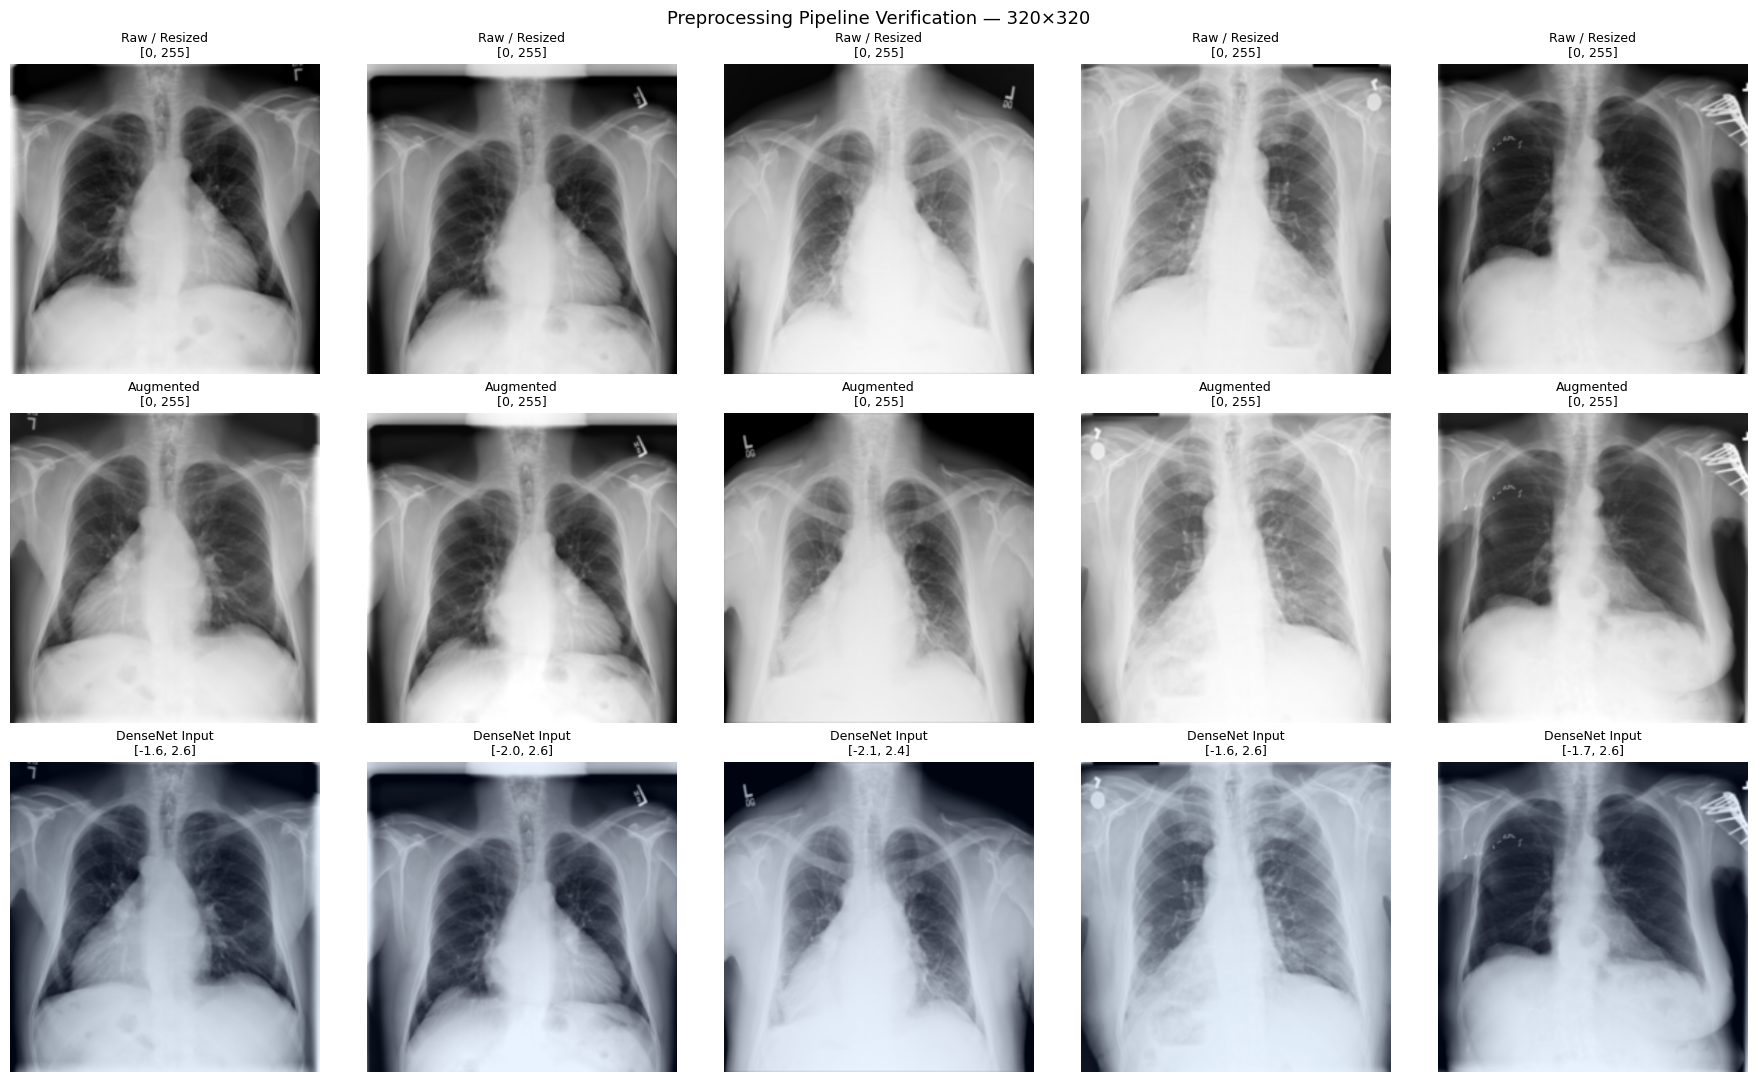

PREPROCESSING VERIFICATION

Validation batch:
  Shape      : (16, 320, 320, 3)
  Min / Max  : -2.118 / 2.631
  Mean / Std : 0.443 / 1.142
  Label dtype: <dtype: 'float32'>
  Label shape: (16, 14)

✓ Preprocessing verification complete.
Saved to: /content/outputs/preprocessing_verification.png


In [ ]:
# ============================================================
# PREPROCESSING VERIFICATION — FINAL 320×320 PIPELINE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs('/content/outputs', exist_ok=True)

IMG_SIZE = 320

fig, axes = plt.subplots(
    3, 5,
    figsize=(18, 11)
)

sample_paths = train_df['image_path'].values[:5]

for col, path in enumerate(sample_paths):

    # ========================================================
    # RAW → RESIZED
    # ========================================================

    raw = tf.io.read_file(path)

    raw = tf.image.decode_png(
        raw,
        channels=3
    )

    raw = tf.image.resize(
        raw,
        [IMG_SIZE, IMG_SIZE]
    )

    raw = tf.cast(
        raw,
        tf.float32
    )

    raw_np = raw.numpy()

    axes[0, col].imshow(
        raw_np / 255.0,
        cmap='gray'
    )

    axes[0, col].set_title(
        'Raw / Resized\n[0, 255]',
        fontsize=9
    )

    axes[0, col].axis('off')


    # ========================================================
    # AUGMENTED RAW IMAGE
    # ========================================================

    dummy_label = tf.zeros(
        NUM_CLASSES,
        dtype=tf.float32
    )

    aug, _ = augment(
        raw,
        dummy_label
    )

    aug_np = aug.numpy()

    axes[1, col].imshow(
        aug_np / 255.0,
        cmap='gray'
    )

    axes[1, col].set_title(
        'Augmented\n[0, 255]',
        fontsize=9
    )

    axes[1, col].axis('off')


    # ========================================================
    # DENSENET PREPROCESSED
    # ========================================================

    proc, _ = preprocess(
        aug,
        dummy_label
    )

    proc_np = proc.numpy()

    # Shift ONLY for visualization
    proc_display = proc_np - proc_np.min()

    if proc_display.max() > 0:
        proc_display = (
            proc_display /
            proc_display.max()
        )

    axes[2, col].imshow(
        proc_display,
        cmap='gray'
    )

    axes[2, col].set_title(
        f'DenseNet Input\n'
        f'[{proc_np.min():.1f}, {proc_np.max():.1f}]',
        fontsize=9
    )

    axes[2, col].axis('off')


# ============================================================
# ROW LABELS
# ============================================================

for row, label in enumerate([
    'Raw / Resized',
    'Augmented',
    'DenseNet Input'
]):

    axes[row, 0].set_ylabel(
        label,
        fontsize=12,
        fontweight='bold',
        rotation=0,
        labelpad=70,
        va='center'
    )


plt.suptitle(
    'Preprocessing Pipeline Verification — 320×320',
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    '/content/outputs/preprocessing_verification.png',
    dpi=150
)

plt.show()


# ============================================================
# NUMERIC SUMMARY
# ============================================================

print("=" * 60)
print("PREPROCESSING VERIFICATION")
print("=" * 60)

for imgs, lbls in val_ds.take(1):

    imgs_np = imgs.numpy()

    print("\nValidation batch:")

    print(
        f"  Shape      : {imgs_np.shape}"
    )

    print(
        f"  Min / Max  : "
        f"{imgs_np.min():.3f} / "
        f"{imgs_np.max():.3f}"
    )

    print(
        f"  Mean / Std : "
        f"{imgs_np.mean():.3f} / "
        f"{imgs_np.std():.3f}"
    )

    print(
        f"  Label dtype: {lbls.dtype}"
    )

    print(
        f"  Label shape: {lbls.shape}"
    )


print("\n✓ Preprocessing verification complete.")
print(
    "Saved to: "
    "/content/outputs/preprocessing_verification.png"
)

In [ ]:
# ============================================================
# CELL 6 — Class Statistics + Weighted BCE Baseline
# ============================================================

import numpy as np
import tensorflow as tf


# ============================================================
# 1. Calculate Positive / Negative Class Statistics
# ============================================================

total = len(train_df)

pos_weights_raw = []

print("=" * 70)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 70)

for cls in CLASSES:

    pos = train_df[cls].sum()
    neg = total - pos

    weight = neg / (pos + 1e-7)

    pos_weights_raw.append(weight)


# ============================================================
# 2. Stabilize Class Weights
# ============================================================
#
# Raw inverse-frequency weights can become extremely large
# for rare diseases such as Hernia.
#
# Square-root scaling reduces extreme weights.
# Maximum weight is capped at 20.
# ============================================================

pos_weights_scaled = [
    min(np.sqrt(w), 20.0)
    for w in pos_weights_raw
]

pos_weights_tensor = tf.constant(
    pos_weights_scaled,
    dtype=tf.float32
)


print("\nClass weights:")
print(
    f"{'Disease':<22}"
    f"{'Positive':>10}"
    f"{'Negative':>10}"
    f"{'Raw Weight':>12}"
    f"{'Scaled':>10}"
)

print("-" * 70)

for cls, raw, scaled in zip(
    CLASSES,
    pos_weights_raw,
    pos_weights_scaled
):

    pos = int(train_df[cls].sum())
    neg = int(total - pos)

    print(
        f"{cls:<22}"
        f"{pos:>10}"
        f"{neg:>10}"
        f"{raw:>12.1f}"
        f"{scaled:>10.2f}"
    )


# ============================================================
# 3. Weighted Binary Cross-Entropy
# ============================================================

class WeightedBCE(tf.keras.losses.Loss):
    """
    Weighted Binary Cross-Entropy baseline.

    Positive examples receive class-specific weights.
    Negative examples retain weight = 1.

    This loss is retained as a baseline.
    The FINAL research model will use Asymmetric Loss (ASL),
    which is defined later in the notebook.
    """

    def __init__(
        self,
        pos_weights,
        label_smoothing=0.05
    ):

        super().__init__()

        self.pos_weights = pos_weights
        self.label_smoothing = label_smoothing


    def call(
        self,
        y_true,
        y_pred
    ):

        y_true = tf.cast(
            y_true,
            tf.float32
        )

        y_pred = tf.cast(
            y_pred,
            tf.float32
        )


        # ----------------------------------------------------
        # Label smoothing
        # ----------------------------------------------------

        y_smooth = (
            y_true * (1.0 - self.label_smoothing)
            + 0.5 * self.label_smoothing
        )


        # ----------------------------------------------------
        # Numerical stability
        # ----------------------------------------------------

        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1.0 - 1e-7
        )


        # ----------------------------------------------------
        # Binary Cross-Entropy
        # ----------------------------------------------------

        bce = -(
            y_smooth * tf.math.log(y_pred)
            +
            (1.0 - y_smooth)
            * tf.math.log(1.0 - y_pred)
        )


        # ----------------------------------------------------
        # Positive-class weighting
        # ----------------------------------------------------

        weight_matrix = tf.where(
            y_true > 0.5,

            tf.ones_like(y_true)
            * self.pos_weights,

            tf.ones_like(y_true)
        )


        bce = bce * weight_matrix


        return tf.reduce_mean(bce)


# ============================================================
# 4. Create Weighted BCE Baseline Loss
# ============================================================

weighted_bce_loss = WeightedBCE(
    pos_weights=pos_weights_tensor,
    label_smoothing=0.05
)

print("\nWeighted BCE baseline loss ready.")


# ============================================================
# 5. Loss Sanity Check
# ============================================================

print("\nLoss sanity checks:")

for imgs, lbls in val_ds.take(1):

    batch_size = lbls.shape[0]


    # --------------------------------------------------------
    # Prediction = 0.1
    # --------------------------------------------------------

    dummy_pred_01 = tf.ones(
        (batch_size, NUM_CLASSES),
        dtype=tf.float32
    ) * 0.1

    loss_01 = weighted_bce_loss(
        lbls,
        dummy_pred_01
    ).numpy()

    print(
        f"  Loss (prediction = 0.1): "
        f"{loss_01:.4f}"
    )


    # --------------------------------------------------------
    # Prediction = 0.5
    # --------------------------------------------------------

    dummy_pred_05 = tf.ones(
        (batch_size, NUM_CLASSES),
        dtype=tf.float32
    ) * 0.5

    loss_05 = weighted_bce_loss(
        lbls,
        dummy_pred_05
    ).numpy()

    print(
        f"  Loss (prediction = 0.5): "
        f"{loss_05:.4f}"
    )


print("\n" + "=" * 70)
print("CELL 6 COMPLETE")
print("=" * 70)

print(
    "\nNOTE:"
    "\nWeighted BCE is retained as a baseline."
    "\nThe final 320×320 research model will use ASL."
)

CLASS IMBALANCE ANALYSIS

Class weights:
Disease                 Positive  Negative  Raw Weight    Scaled
----------------------------------------------------------------------
Atelectasis                 8175     70391         8.6      2.93
Cardiomegaly                1888     76678        40.6      6.37
Effusion                    9433     69133         7.3      2.71
Infiltration               13849     64717         4.7      2.16
Mass                        4239     74327        17.5      4.19
Nodule                      4425     74141        16.8      4.09
Pneumonia                    936     77630        82.9      9.11
Pneumothorax                3768     74798        19.9      4.46
Consolidation               3228     75338        23.3      4.83
Edema                       1630     76936        47.2      6.87
Emphysema                   1666     76900        46.2      6.79
Fibrosis                    1156     77410        67.0      8.18
Pleural_Thickening          2379     76187 

In [ ]:
# ============================================================
# CELL 7 — Build Model
# DenseNet-121 + Classification Head
# Final input resolution: 320 × 320
# ============================================================

def build_model(num_classes=NUM_CLASSES):
    """
    Build the baseline DenseNet-121 multi-label classifier.

    Architecture:
        Input (320×320×3)
            ↓
        DenseNet-121 ImageNet backbone
            ↓
        Global Average Pooling
            ↓
        BatchNorm
            ↓
        Dropout(0.5)
            ↓
        Dense(512, ReLU)
            ↓
        BatchNorm
            ↓
        Dropout(0.3)
            ↓
        Dense(14, Sigmoid)

    The same head structure is retained in the later
    ASL + uncertainty pipeline so weights remain compatible.
    """

    # --------------------------------------------------------
    # 1. DenseNet-121 backbone
    # --------------------------------------------------------
    base = tf.keras.applications.DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # Frozen for initial head-training phase
    base.trainable = False

    # --------------------------------------------------------
    # 2. Classification head
    # --------------------------------------------------------
    inputs = tf.keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name='input_image'
    )

    # Keep backbone BatchNorm layers in inference mode.
    # This is also useful later for MC Dropout experiments.
    x = base(inputs, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D(
        name='gap'
    )(x)

    x = tf.keras.layers.BatchNormalization(
        name='head_bn'
    )(x)

    x = tf.keras.layers.Dropout(
        0.5,
        name='drop1'
    )(x)

    x = tf.keras.layers.Dense(
        512,
        activation='relu',
        name='fc1'
    )(x)

    x = tf.keras.layers.BatchNormalization(
        name='fc_bn'
    )(x)

    x = tf.keras.layers.Dropout(
        0.3,
        name='drop2'
    )(x)

    # Keep final predictions in float32 when mixed precision
    # is enabled for numerical stability.
    outputs = tf.keras.layers.Dense(
        num_classes,
        activation='sigmoid',
        dtype='float32',
        name='predictions'
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='CheXNet_DenseNet121_320'
    )

    return model, base


# ============================================================
# BUILD MODEL
# ============================================================

model, base_model = build_model()

print("=" * 65)
print("MODEL ARCHITECTURE")
print("=" * 65)

model.summary(line_length=100)

total_params = model.count_params()
trainable_params = sum(
    tf.size(v).numpy()
    for v in model.trainable_variables
)

print("\n" + "=" * 65)
print(f"Input resolution : {IMG_SIZE} × {IMG_SIZE}")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Total parameters : {total_params:,}")
print(f"Trainable params : {trainable_params:,}")
print(f"Backbone layers  : {len(base_model.layers)}")
print(f"Backbone frozen  : {not base_model.trainable}")
print("=" * 65)

# ============================================================
# ARCHITECTURE SANITY CHECKS
# ============================================================

assert IMG_SIZE == 320, \
    f"Expected IMG_SIZE=320, got {IMG_SIZE}"

assert model.input_shape == (None, 320, 320, 3), \
    f"Unexpected input shape: {model.input_shape}"

assert model.output_shape == (None, NUM_CLASSES), \
    f"Unexpected output shape: {model.output_shape}"

assert model.get_layer('drop1').rate == 0.5
assert model.get_layer('drop2').rate == 0.3

assert model.get_layer('predictions').activation.__name__ == 'sigmoid'

print("\n✓ Input shape verified: 320 × 320 × 3")
print(f"✓ Output shape verified: 14 disease probabilities")
print("✓ DenseNet-121 backbone frozen")
print("✓ Dropout layers present for later MC Dropout")
print("✓ Final layer uses sigmoid for multi-label classification")
print("\nCell 7 complete.")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MODEL ARCHITECTURE


Model: "CheXNet_DenseNet121_320"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)                   │ (None, 320, 320, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ densenet121 (Functional)                   │ (None, 10, 10, 1024)            │         7,037,504 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ gap (GlobalAveragePooling2D)               │ (None, 1024)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ head_bn (BatchNormalization)               │ (None, 1024)                    │             4,096 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ drop1 (Dropout)                            │ (None, 1024)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ fc1 (Dense)                                │ (None, 512)                     │           524,800 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ fc_bn (BatchNormalization)                 │ (None, 512)                     │             2,048 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ drop2 (Dropout)                            │ (None, 512)                     │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ predictions (Dense)                        │ (None, 14)                      │             7,182 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 7,575,630 (28.90 MB)

 Trainable params: 535,054 (2.04 MB)

 Non-trainable params: 7,040,576 (26.86 MB)


Input resolution : 320 × 320
Number of classes: 14
Total parameters : 7,575,630
Trainable params : 535,054
Backbone layers  : 427
Backbone frozen  : True

✓ Input shape verified: 320 × 320 × 3
✓ Output shape verified: 14 disease probabilities
✓ DenseNet-121 backbone frozen
✓ Dropout layers present for later MC Dropout
✓ Final layer uses sigmoid for multi-label classification

Cell 7 complete.


In [ ]:
# ============================================================
# CELL 8A — ASYMMETRIC LOSS (ASL)
# ============================================================

class AsymmetricLoss(tf.keras.losses.Loss):

    def __init__(
        self,
        gamma_neg=4.0,
        gamma_pos=1.0,
        clip=0.05,
        eps=1e-8,
        name="asymmetric_loss"
    ):
        super().__init__(name=name)

        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def call(self, y_true, y_pred):

        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # Numerical stability
        y_pred = tf.clip_by_value(
            y_pred,
            self.eps,
            1.0 - self.eps
        )

        # Positive probability
        xs_pos = y_pred

        # Negative probability
        xs_neg = 1.0 - y_pred

        # Asymmetric clipping
        if self.clip > 0:
            xs_neg = tf.clip_by_value(
                xs_neg + self.clip,
                0.0,
                1.0
            )

        # Basic CE
        loss = (
            y_true * tf.math.log(xs_pos)
            +
            (1.0 - y_true) * tf.math.log(xs_neg)
        )

        # ----------------------------------------------------
        # Asymmetric focusing
        # ----------------------------------------------------
        pt = (
            xs_pos * y_true
            +
            xs_neg * (1.0 - y_true)
        )

        gamma = (
            self.gamma_pos * y_true
            +
            self.gamma_neg * (1.0 - y_true)
        )

        asymmetric_w = tf.pow(
            1.0 - pt,
            gamma
        )

        loss *= asymmetric_w

        return -tf.reduce_mean(loss)


# ------------------------------------------------------------
# Initialize ASL
# ------------------------------------------------------------
loss_fn = AsymmetricLoss(
    gamma_neg=4.0,
    gamma_pos=1.0,
    clip=0.05
)

print("✓ ASL initialized")
print(f"  gamma_neg : {loss_fn.gamma_neg}")
print(f"  gamma_pos : {loss_fn.gamma_pos}")
print(f"  clip      : {loss_fn.clip}")
print(f"  classes   : {NUM_CLASSES}")

✓ ASL initialized
  gamma_neg : 4.0
  gamma_pos : 1.0
  clip      : 0.05
  classes   : 14


In [ ]:
# ============================================================
# CELL 8 — PHASE 1: Train Head Only (DenseNet-121 frozen)
#           Target: Healthy validation AUC before Phase 2
# ============================================================

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------
optimizer_p1 = tf.keras.optimizers.Adam(
    learning_rate=1e-3
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
train_loss_m = tf.keras.metrics.Mean(name='train_loss')

val_loss_m = tf.keras.metrics.Mean(name='val_loss')

val_auc_m = tf.keras.metrics.AUC(
    num_thresholds=200,
    multi_label=True,
    num_labels=NUM_CLASSES,
    name='val_auc'
)

# ------------------------------------------------------------
# Training step
# ------------------------------------------------------------
@tf.function
def train_step_p1(images, labels):

    with tf.GradientTape() as tape:

        preds = model(images, training=True)
        preds = tf.cast(preds, tf.float32)

        loss = loss_fn(labels, preds)

    grads = tape.gradient(
        loss,
        model.trainable_variables
    )

    optimizer_p1.apply_gradients(
        zip(grads, model.trainable_variables)
    )

    train_loss_m.update_state(loss)


# ------------------------------------------------------------
# Validation step
# ------------------------------------------------------------
@tf.function
def val_step(images, labels):

    preds = model(images, training=False)
    preds = tf.cast(preds, tf.float32)

    loss = loss_fn(labels, preds)

    val_loss_m.update_state(loss)
    val_auc_m.update_state(labels, preds)


# ------------------------------------------------------------
# Phase 1 configuration
# ------------------------------------------------------------
P1_EPOCHS = 5

best_auc = 0.0

history = {
    'train_loss': [],
    'val_loss': [],
    'val_auc': []
}

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
OUTPUT_DIR = '/content/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# Start Phase 1
# ------------------------------------------------------------
print("PHASE 1 — Head training (DenseNet-121 frozen)")
print(f"Epochs: {P1_EPOCHS}  |  LR: 1e-3")
print(f"Loss function: {loss_fn}")
print(f"Output directory: {OUTPUT_DIR}")
print("=" * 70)


for epoch in range(P1_EPOCHS):

    t0 = time.time()

    # Reset metrics
    train_loss_m.reset_state()
    val_loss_m.reset_state()
    val_auc_m.reset_state()

    # ========================================================
    # TRAIN
    # ========================================================
    for step, (imgs, lbls) in enumerate(train_ds):

        train_step_p1(imgs, lbls)

        if step % 300 == 0:

            print(
                f"  ep{epoch+1} "
                f"step {step:>4}/{len(train_ds)} "
                f"| loss {train_loss_m.result():.4f}"
            )

    # ========================================================
    # VALIDATION
    # ========================================================
    for imgs, lbls in val_ds:

        val_step(imgs, lbls)

    # --------------------------------------------------------
    # Epoch results
    # --------------------------------------------------------
    tl = float(train_loss_m.result().numpy())
    vl = float(val_loss_m.result().numpy())
    va = float(val_auc_m.result().numpy())

    history['train_loss'].append(tl)
    history['val_loss'].append(vl)
    history['val_auc'].append(va)

    elapsed = time.time() - t0

    print(
        f"\nEpoch {epoch+1}/{P1_EPOCHS} "
        f"| train_loss={tl:.4f} "
        f"| val_loss={vl:.4f} "
        f"| val_auc={va:.4f} "
        f"| time={elapsed:.0f}s"
    )

    # ========================================================
    # Save epoch checkpoint
    # ========================================================
    epoch_path = os.path.join(
        OUTPUT_DIR,
        f'p1_ep{epoch+1}.keras'
    )

    model.save(epoch_path)

    print(f"  ✓ checkpoint saved: {epoch_path}")

    # ========================================================
    # Save best model
    # ========================================================
    if va > best_auc:

        best_auc = va

        best_path = os.path.join(
            OUTPUT_DIR,
            'best_p1.keras'
        )

        model.save(best_path)

        print(
            f"  ✓ best Phase 1 model saved "
            f"(AUC {best_auc:.4f})"
        )

    # ========================================================
    # Safety check
    # ========================================================
    if vl > 2.0:

        print(
            f"\n  ✗ ABORT: val_loss={vl:.4f} > 2.0"
        )

        print(
            "  Possible preprocessing/loss/pipeline issue."
        )

        print(
            "  Check the preprocessing and loss configuration "
            "before continuing."
        )

        break

    print("-" * 70)


# ============================================================
# FINAL PHASE 1 STATUS
# ============================================================
print("\n" + "=" * 70)
print(f"Phase 1 complete.")
print(f"Best validation AUC: {best_auc:.4f}")
print("=" * 70)

if best_auc < 0.68:

    print("\n⚠ AUC below 0.68 after Phase 1.")
    print("DO NOT run Phase 2 yet.")
    print("Run the diagnostic cell before continuing.")

else:

    print("✓ Phase 1 looks healthy.")
    print("✓ Safe to proceed to Phase 2.")

PHASE 1 — Head training (DenseNet-121 frozen)
Epochs: 5  |  LR: 1e-3
Loss function: <__main__.AsymmetricLoss object at 0x7bf2af863230>
Output directory: /content/outputs
  ep1 step    0/4911 | loss 0.3073
  ep1 step  300/4911 | loss 0.1094
  ep1 step  600/4911 | loss 0.0819
  ep1 step  900/4911 | loss 0.0690
  ep1 step 1200/4911 | loss 0.0612
  ep1 step 1500/4911 | loss 0.0560
  ep1 step 1800/4911 | loss 0.0523
  ep1 step 2100/4911 | loss 0.0496
  ep1 step 2400/4911 | loss 0.0473
  ep1 step 2700/4911 | loss 0.0456
  ep1 step 3000/4911 | loss 0.0443
  ep1 step 3300/4911 | loss 0.0431
  ep1 step 3600/4911 | loss 0.0422
  ep1 step 3900/4911 | loss 0.0414
  ep1 step 4200/4911 | loss 0.0407
  ep1 step 4500/4911 | loss 0.0400
  ep1 step 4800/4911 | loss 0.0395

Epoch 1/5 | train_loss=0.0393 | val_loss=0.0298 | val_auc=0.7102 | time=715s
  ✓ checkpoint saved: /content/outputs/p1_ep1.keras
  ✓ best Phase 1 model saved (AUC 0.7102)
---------------------------------------------------------------

In [ ]:
print("GPU:")
print(tf.config.list_physical_devices('GPU'))

print("\nTrain batches:", len(train_ds))
print("Val batches:", len(val_ds))

print("\nTrainable parameters:")
print(model.count_params())

GPU:
[]

Train batches: 4911
Val batches: 1067

Trainable parameters:
7575630


In [ ]:
# ============================================================
# CELL 9 — PHASE 2: ASL + GRADUAL DENSENET-121 FINE-TUNING
# ============================================================

import os
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras

print("=" * 70)
print("PHASE 2 — Gradual DenseNet-121 Fine-Tuning")
print("=" * 70)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

IMG_SIZE_P2 = 320
NUM_CLASSES = 14

P2_EPOCHS = 15

# Conservative fine-tuning LR
BASE_LR = 1e-5

# Warmup for the first few epochs
WARMUP_EPOCHS = 2

# Gradual unfreezing schedule
# epoch number : number of DenseNet layers to unfreeze
UNFREEZE_SCHEDULE = {
    1: 60,
    5: 120,
    9: 200,
    13: 300,
}

PATIENCE = 5
MIN_DELTA = 0.001

OUTPUT_DIR = "/content/outputs"

BEST_P1 = os.path.join(OUTPUT_DIR, "best_p1.keras")
BEST_P2 = os.path.join(OUTPUT_DIR, "best_p2.keras")

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Image size       : {IMG_SIZE_P2}x{IMG_SIZE_P2}")
print(f"Epochs           : {P2_EPOCHS}")
print(f"Base LR          : {BASE_LR}")
print(f"Warmup epochs    : {WARMUP_EPOCHS}")
print(f"Loss             : {loss_fn}")
print(f"Starting model   : {BEST_P1}")
print(f"Output directory : {OUTPUT_DIR}")
print()


# ------------------------------------------------------------
# 2. Load best Phase 1 model
# ------------------------------------------------------------

print("Loading best Phase 1 model...")

model = keras.models.load_model(
    BEST_P1,
    compile=False
)

print("✓ Phase 1 checkpoint loaded")
print(f"Model: {model.name}")


# ------------------------------------------------------------
# 3. Verify input/output compatibility
# ------------------------------------------------------------

print()
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

assert model.input_shape[1:] == (320, 320, 3), \
    f"Expected (320,320,3), got {model.input_shape[1:]}"

assert model.output_shape[-1] == NUM_CLASSES, \
    f"Expected {NUM_CLASSES} outputs, got {model.output_shape[-1]}"

print("✓ 320x320 / 14-class configuration confirmed")


# ------------------------------------------------------------
# 4. Locate DenseNet backbone
# ------------------------------------------------------------

base_model = model.get_layer("densenet121")

print()
print("DenseNet backbone found:")
print("Name  :", base_model.name)
print("Layers:", len(base_model.layers))


# ------------------------------------------------------------
# 5. Keep BatchNorm layers in inference mode
# ------------------------------------------------------------
#
# During fine-tuning we don't want the medical-image dataset
# to aggressively modify ImageNet BatchNorm statistics.
#
# The model architecture already calls:
#
#     base(inputs, training=False)
#
# so this reinforces that strategy.

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False


# ------------------------------------------------------------
# 6. Initially freeze entire backbone
# ------------------------------------------------------------

base_model.trainable = False

print()
print("Initial state:")
print("DenseNet trainable:", base_model.trainable)
print("Trainable params   :", model.count_params())


# ------------------------------------------------------------
# 7. Optimizer
# ------------------------------------------------------------

optimizer = keras.optimizers.Adam(
    learning_rate=BASE_LR,
    clipnorm=1.0
)


# ------------------------------------------------------------
# 8. Metrics
# ------------------------------------------------------------

def calculate_multilabel_auc(y_true, y_pred):
    """
    Macro ROC-AUC across the 14 disease labels.
    """
    auc = tf.keras.metrics.AUC(
        multi_label=True,
        num_labels=NUM_CLASSES,
        curve="ROC"
    )

    auc.update_state(y_true, y_pred)
    return auc.result()


# ------------------------------------------------------------
# 9. Learning-rate schedule
# ------------------------------------------------------------

def get_learning_rate(epoch):
    """
    Linear warmup followed by cosine decay.
    """

    if epoch < WARMUP_EPOCHS:
        # Start at 20% of BASE_LR
        progress = (epoch + 1) / WARMUP_EPOCHS
        return BASE_LR * (0.2 + 0.8 * progress)

    decay_epochs = P2_EPOCHS - WARMUP_EPOCHS

    if decay_epochs <= 0:
        return BASE_LR

    progress = (
        (epoch - WARMUP_EPOCHS) /
        float(decay_epochs)
    )

    progress = np.clip(progress, 0.0, 1.0)

    cosine = 0.5 * (
        1.0 + np.cos(np.pi * progress)
    )

    return BASE_LR * cosine


# ------------------------------------------------------------
# 10. Unfreeze helper
# ------------------------------------------------------------

def unfreeze_top_layers(n_layers):
    """
    Unfreeze the top N DenseNet layers while keeping all
    BatchNorm layers frozen.
    """

    # First freeze everything
    for layer in base_model.layers:
        layer.trainable = False

    # Unfreeze last N layers
    for layer in base_model.layers[-n_layers:]:
        if not isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = True

    # Count trainable DenseNet layers
    trainable_backbone = sum(
        1 for layer in base_model.layers
        if layer.trainable
    )

    return trainable_backbone


# ------------------------------------------------------------
# 11. Custom train step
# ------------------------------------------------------------

def make_train_step():

    @tf.function(
        reduce_retracing=True
    )
    def train_step(images, labels):

        with tf.GradientTape() as tape:

            predictions = model(
                images,
                training=True
            )

            loss = loss_fn(
                labels,
                predictions
            )

            # Include regularization losses if present
            if model.losses:
                loss += tf.add_n(model.losses)

        trainable_vars = model.trainable_variables

        gradients = tape.gradient(
            loss,
            trainable_vars
        )

        optimizer.apply_gradients(
            zip(gradients, trainable_vars)
        )

        return loss, predictions

    return train_step


# ------------------------------------------------------------
# 12. Validation
# ------------------------------------------------------------

@tf.function(
    reduce_retracing=True
)
def validation_step(images, labels):

    predictions = model(
        images,
        training=False
    )

    loss = loss_fn(
        labels,
        predictions
    )

    return loss, predictions


# ------------------------------------------------------------
# 13. Training configuration
# ------------------------------------------------------------

best_auc = -np.inf
best_epoch = 0
epochs_without_improvement = 0

history_p2 = {
    "train_loss": [],
    "val_loss": [],
    "val_auc": [],
    "lr": [],
}

print()
print("=" * 70)
print("PHASE 2 TRAINING START")
print("=" * 70)
print()
print("Unfreeze schedule:")

for ep, layers in UNFREEZE_SCHEDULE.items():
    print(f"  Epoch {ep:02d} → top {layers} DenseNet layers")

print()
print("⚠️ BatchNorm layers remain frozen.")
print("⚠️ Loss = current ASL loss_fn.")
print()


# ------------------------------------------------------------
# 14. Main training loop
# ------------------------------------------------------------

for epoch in range(1, P2_EPOCHS + 1):

    epoch_start = time.time()

    # --------------------------------------------------------
    # Gradual unfreezing
    # --------------------------------------------------------

    if epoch in UNFREEZE_SCHEDULE:

        n_layers = UNFREEZE_SCHEDULE[epoch]

        trainable_backbone = unfreeze_top_layers(
            n_layers
        )

        # IMPORTANT:
        # Recreate tf.function after trainable-variable changes
        # so newly unfrozen variables are included correctly.
        train_step = make_train_step()

        print()
        print("-" * 70)
        print(
            f"Epoch {epoch}: "
            f"unfreezing top {n_layers} DenseNet layers"
        )
        print(
            f"Trainable DenseNet layers: "
            f"{trainable_backbone}"
        )
        print(
            f"Total trainable parameters: "
            f"{np.sum([np.prod(v.shape) for v in model.trainable_variables]):,}"
        )
        print("-" * 70)

    # --------------------------------------------------------
    # Learning rate
    # --------------------------------------------------------

    current_lr = get_learning_rate(epoch - 1)

    optimizer.learning_rate.assign(
        current_lr
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss_total = 0.0
    train_batches = 0

    total_train_steps = tf.data.experimental.cardinality(
        train_ds
    ).numpy()

    for step, (images, labels) in enumerate(train_ds):

        loss_value, predictions = train_step(
            images,
            labels
        )

        train_loss_total += float(loss_value)
        train_batches += 1

        if step % 300 == 0:
            print(
                f"  ep{epoch} "
                f"step {step:4d}/{total_train_steps} "
                f"| loss {float(loss_value):.4f}"
            )

    train_loss = (
        train_loss_total /
        max(train_batches, 1)
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss_total = 0.0
    val_batches = 0

    val_auc_metric = tf.keras.metrics.AUC(
        multi_label=True,
        num_labels=NUM_CLASSES,
        curve="ROC"
    )

    for images, labels in val_ds:

        loss_value, predictions = validation_step(
            images,
            labels
        )

        val_loss_total += float(loss_value)
        val_batches += 1

        val_auc_metric.update_state(
            labels,
            predictions
        )

    val_loss = (
        val_loss_total /
        max(val_batches, 1)
    )

    val_auc = float(
        val_auc_metric.result()
    )

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history_p2["train_loss"].append(
        train_loss
    )

    history_p2["val_loss"].append(
        val_loss
    )

    history_p2["val_auc"].append(
        val_auc
    )

    history_p2["lr"].append(
        current_lr
    )

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print()
    print(
        f"Epoch {epoch}/{P2_EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_auc={val_auc:.4f} | "
        f"lr={current_lr:.2e} | "
        f"time={epoch_time:.0f}s"
    )

    # --------------------------------------------------------
    # Save epoch checkpoint
    # --------------------------------------------------------

    epoch_path = os.path.join(
        OUTPUT_DIR,
        f"p2_ep{epoch}.keras"
    )

    model.save(epoch_path)

    print(
        f"  ✓ checkpoint saved: {epoch_path}"
    )

    # --------------------------------------------------------
    # Best checkpoint
    # --------------------------------------------------------

    if val_auc > best_auc + MIN_DELTA:

        best_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0

        model.save(BEST_P2)

        print(
            f"  ✓ BEST Phase 2 model saved "
            f"(AUC {best_auc:.4f})"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  No significant improvement "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if epochs_without_improvement >= PATIENCE:

        print()
        print("=" * 70)
        print("EARLY STOPPING")
        print("=" * 70)
        print(
            f"No significant AUC improvement for "
            f"{PATIENCE} epochs."
        )
        print(
            f"Best AUC: {best_auc:.4f} "
            f"(epoch {best_epoch})"
        )

        break

    print("-" * 70)


# ============================================================
# PHASE 2 SUMMARY
# ============================================================

print()
print("=" * 70)
print("PHASE 2 COMPLETE")
print("=" * 70)

print(
    f"Best validation AUC : {best_auc:.4f}"
)

print(
    f"Best epoch          : {best_epoch}"
)

print(
    f"Best checkpoint     : {BEST_P2}"
)

print()
print("✓ Phase 2 finished.")
print("✓ Current experiment remains 320x320 + ASL.")
print("✓ BatchNorm layers remained frozen.")
print("✓ Best model saved for the next phase.")
print("=" * 70)

PHASE 2 — Gradual DenseNet-121 Fine-Tuning
Image size       : 320x320
Epochs           : 15
Base LR          : 1e-05
Warmup epochs    : 2
Loss             : <__main__.AsymmetricLoss object at 0x7bf2af863230>
Starting model   : /content/outputs/best_p1.keras
Output directory : /content/outputs

Loading best Phase 1 model...
✓ Phase 1 checkpoint loaded
Model: CheXNet_DenseNet121_320

Model input shape : (None, 320, 320, 3)
Model output shape: (None, 14)
✓ 320x320 / 14-class configuration confirmed

DenseNet backbone found:
Name  : densenet121
Layers: 427

Initial state:
DenseNet trainable: False
Trainable params   : 7575630

PHASE 2 TRAINING START

Unfreeze schedule:
  Epoch 01 → top 60 DenseNet layers
  Epoch 05 → top 120 DenseNet layers
  Epoch 09 → top 200 DenseNet layers
  Epoch 13 → top 300 DenseNet layers

⚠️ BatchNorm layers remain frozen.
⚠️ Loss = current ASL loss_fn.


----------------------------------------------------------------------
Epoch 1: unfreezing top 60 DenseNet lay


Epoch 1/15 | train_loss=0.0282 | val_loss=0.0275 | val_auc=0.7752 | lr=6.00e-06 | time=957s
  ✓ checkpoint saved: /content/outputs/p2_ep1.keras
  ✓ BEST Phase 2 model saved (AUC 0.7752)
----------------------------------------------------------------------
  ep2 step    0/4911 | loss 0.0285
  ep2 step  300/4911 | loss 0.0336
  ep2 step  600/4911 | loss 0.0247
  ep2 step  900/4911 | loss 0.0285
  ep2 step 1200/4911 | loss 0.0267
  ep2 step 1500/4911 | loss 0.0246
  ep2 step 1800/4911 | loss 0.0279
  ep2 step 2100/4911 | loss 0.0164
  ep2 step 2400/4911 | loss 0.0174
  ep2 step 2700/4911 | loss 0.0302
  ep2 step 3000/4911 | loss 0.0162
  ep2 step 3300/4911 | loss 0.0394
  ep2 step 3600/4911 | loss 0.0118
  ep2 step 3900/4911 | loss 0.0320
  ep2 step 4200/4911 | loss 0.0267
  ep2 step 4500/4911 | loss 0.0175
  ep2 step 4800/4911 | loss 0.0375

Epoch 2/15 | train_loss=0.0280 | val_loss=0.0273 | val_auc=0.7809 | lr=1.00e-05 | time=927s
  ✓ checkpoint saved: /content/outputs/p2_ep2.keras
  

ValueError: in user code:

    File "/tmp/ipykernel_1869/835632414.py", line 256, in train_step  *
        optimizer.apply_gradients(
    File "/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py", line 462, in apply_gradients  **
        self.apply(grads, trainable_variables)
    File "/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py", line 503, in apply
        self._check_variables_are_known(trainable_variables)
    File "/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py", line 408, in _check_variables_are_known
        raise ValueError(

    ValueError: Unknown variable: <Variable path=conv4_block24_2_conv/kernel, shape=(3, 3, 128, 32), dtype=float32>. This optimizer can only be called for the variables it was originally built with. When working with a new set of variables, you should recreate a new optimizer instance.


In [ ]:
from google.colab import files

files.download("/content/outputs/best_p2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# FINAL CELL — Grad-CAM Visualization
# Current experiment: DenseNet-121 + ASL + 320x320
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
IMG_SIZE = 320
OUTPUT_DIR = "/content/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use the current best Phase 2 model already loaded in memory.
# If your notebook calls it "model", this will use model.
# If it calls it "eval_model", that will also work.
if "eval_model" in globals():
    gradcam_model = eval_model
elif "model" in globals():
    gradcam_model = model
else:
    raise NameError(
        "No model found. Make sure your Phase 2 model is loaded "
        "as `model` or `eval_model` before running this cell."
    )

print("Grad-CAM model:", gradcam_model.name)
print("Input shape   :", gradcam_model.input_shape)
print("Output shape  :", gradcam_model.output_shape)

# ------------------------------------------------------------
# 2. Locate DenseNet-121 and final convolutional layer
# ------------------------------------------------------------
densenet = gradcam_model.get_layer("densenet121")

# Final convolutional feature layer of DenseNet-121
last_conv_name = "conv5_block16_2_conv"
last_conv = densenet.get_layer(last_conv_name)

print(f"\nGrad-CAM target layer: {last_conv_name}")
print(f"Feature map shape: {last_conv.output.shape}")

# IMPORTANT:
# Build the Grad-CAM model from the FULL model input.
# This keeps the convolutional feature map and prediction
# inside the same computational graph.
grad_model = tf.keras.Model(
    inputs=gradcam_model.input,
    outputs=[
        last_conv.output,
        gradcam_model.output
    ]
)

print("✓ Grad-CAM model created successfully")


# ------------------------------------------------------------
# 3. Grad-CAM function
# ------------------------------------------------------------
def get_gradcam(img_tensor, class_idx):
    """
    img_tensor:
        Shape (1, 320, 320, 3), DenseNet-preprocessed.

    class_idx:
        Index of target disease.

    Returns:
        2D heatmap in [0, 1].
    """

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_tensor,
            training=False
        )

        # Class-specific sigmoid probability
        class_score = predictions[:, class_idx]

    # Gradient of target disease score with respect
    # to the final convolutional feature maps
    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradients are None. Check Grad-CAM layer/model connectivity."
        )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU: only positive influence
    heatmap = tf.maximum(heatmap, 0)

    # Normalize
    max_value = tf.reduce_max(heatmap)

    if max_value > 1e-8:
        heatmap = heatmap / max_value
    else:
        heatmap = tf.ones_like(heatmap) * 0.5

    return heatmap.numpy().astype(np.float32)


# ------------------------------------------------------------
# 4. Overlay function
# ------------------------------------------------------------
def make_overlay(img_disp, heatmap):
    """
    img_disp:
        320x320x3 image in [0,1]

    heatmap:
        Grad-CAM heatmap in [0,1]

    Returns:
        320x320x3 RGB uint8 overlay.
    """

    heatmap_resized = cv2.resize(
        heatmap,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    heatmap_uint8 = np.uint8(
        255 * np.clip(heatmap_resized, 0, 1)
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    image_uint8 = np.uint8(
        255 * np.clip(img_disp, 0, 1)
    )

    overlay = cv2.addWeighted(
        image_uint8,
        0.60,
        heatmap_color,
        0.40,
        0
    )

    return overlay


# ------------------------------------------------------------
# 5. Select positive test/validation examples
# ------------------------------------------------------------
sample_classes = [
    "Cardiomegaly",
    "Effusion",
    "Pneumothorax",
    "Atelectasis"
]

sample_classes = [
    c for c in sample_classes
    if c in CLASSES
]

print("\nVisualising:", sample_classes)

# Prefer test set
if "test_df" in globals():
    source_df = test_df
    source_name = "test"
else:
    source_df = val_df
    source_name = "validation"

print(f"Using {source_name} dataset.")


# ------------------------------------------------------------
# 6. Generate Grad-CAM visualizations
# ------------------------------------------------------------
fig, axes = plt.subplots(
    len(sample_classes),
    3,
    figsize=(12, 4 * len(sample_classes))
)

if len(sample_classes) == 1:
    axes = axes[np.newaxis, :]

for row, cls_name in enumerate(sample_classes):

    cls_idx = CLASSES.index(cls_name)

    # Find positive sample
    positive_rows = source_df[
        source_df[cls_name] == 1
    ]

    if len(positive_rows) == 0:
        print(f"⚠ No positive sample found for {cls_name}")

        for ax in axes[row]:
            ax.axis("off")

        continue

    img_path = positive_rows.iloc[0]["image_path"]

    try:
        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------
        raw = tf.io.read_file(img_path)

        raw = tf.image.decode_image(
            raw,
            channels=3,
            expand_animations=False
        )

        raw = tf.image.resize(
            raw,
            [IMG_SIZE, IMG_SIZE]
        )

        raw = tf.cast(raw, tf.float32)

        # Display version
        disp = (
            raw.numpy() / 255.0
        ).astype(np.float32)

        # ----------------------------------------------------
        # DenseNet preprocessing
        # ----------------------------------------------------
        processed = tf.keras.applications.densenet.preprocess_input(
            raw
        )

        img_tensor = tf.expand_dims(
            processed,
            axis=0
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------
        predictions = gradcam_model(
            img_tensor,
            training=False
        ).numpy()[0]

        pred = float(
            predictions[cls_idx]
        )

        # ----------------------------------------------------
        # Grad-CAM
        # ----------------------------------------------------
        heatmap = get_gradcam(
            img_tensor,
            cls_idx
        )

        overlay = make_overlay(
            disp,
            heatmap
        )

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------
        axes[row, 0].imshow(
            disp,
            cmap="gray"
        )
        axes[row, 0].set_title(
            f"Original\n{cls_name}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(
            heatmap,
            cmap="jet",
            vmin=0,
            vmax=1
        )
        axes[row, 1].set_title(
            f"Grad-CAM\nP = {pred:.3f}"
        )
        axes[row, 1].axis("off")

        axes[row, 2].imshow(
            overlay
        )
        axes[row, 2].set_title(
            "Grad-CAM Overlay"
        )
        axes[row, 2].axis("off")

        print(
            f"✓ {cls_name:<20} "
            f"prediction={pred:.4f}  "
            f"heatmap=[{heatmap.min():.3f}, "
            f"{heatmap.max():.3f}]"
        )

    except Exception as e:

        print(
            f"✗ Grad-CAM failed for "
            f"{cls_name}: {e}"
        )

        for ax in axes[row]:
            ax.axis("off")

        axes[row, 0].set_title(
            f"{cls_name}\nFAILED"
        )


# ------------------------------------------------------------
# 7. Save figure
# ------------------------------------------------------------
plt.suptitle(
    "Grad-CAM — Disease-Specific Localization",
    fontsize=15
)

plt.tight_layout()

output_path = os.path.join(
    OUTPUT_DIR,
    "gradcam_current_model.png"
)

plt.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 60)
print("Grad-CAM visualization complete.")
print(f"Saved to: {output_path}")
print("=" * 60)

NameError: No model found. Make sure your Phase 2 model is loaded as `model` or `eval_model` before running this cell.